# MCP 실습: 에이전트에 붙이는 MCP 도구를 하나에서 셋으로 늘리기

**이 노트북에서 할 일**

1. 앞 절에서 배운 서버에 도구 붙이기·에이전트 연결·입력 토큰 세기를 한 흐름에 모읍니다.
2. 서버가 알린 도구 셋 가운데 하나를 붙인 실행 1과, 셋을 모두 붙인 실행 2를 차례로 실행합니다.
3. 두 실행의 입력 토큰을 요청마다 견주어, 붙인 도구의 명세가 어느 요청에 실리는지 봅니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 실행 1과 실행 2에서 에이전트를 한 번씩 실행합니다.
노트북 밖에서 두 실행을 다섯 번씩 보냈을 때, 요청은 열 번 모두 실행마다 2번이었습니다.
그래서 이 노트북의 모델 요청은 모두 4번으로 어림합니다.
호출 한도 3을 붙여, 한 실행의 요청이 3번을 넘지 않게 막습니다.

요금표로 어림한 예상 비용은 두 실행을 합쳐 0.002달러 아래이고, 청구 금액이 아닙니다.
서버는 서버 파일 `course_server.py`를 이 커널에서 읽어 메모리 연결로 붙입니다.
자식 프로세스는 띄우지 않고, 노트북이 쓰는 파일도 없습니다.
모델이 쓰는 도구 인자와 답 글은 실행마다 달라질 수 있고, 걸린 시간은 재지 않았습니다.
앞에서 배운 함수 다섯은 도구 파일 `connect_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
패키지 fastmcp 4.0.3, mcp 2.2.0, python-dotenv 1.2.3도 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었고, 다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**실습 범위** — 이 절은 이 챕터의 실습이고, 30분 안팎입니다.
따로 내는 과제는 없고, 강사와 함께 첫 셀부터 차례로 실행합니다.

실습 폴더 `labs/part6/ch28-mcp`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 서버 객체 server 서버 파일 도구 lookup_policy + @server.tool 둘에서 파란 상자 MCPAdapter list_tools 메모리 연결, 노란 상자 서버가 알린 도구 셋 lookup_policy · search_topics · show_topics, 파란 상자 바꾸는 값 tool_count 실행 1은 1 · 실행 2는 3으로 화살표가 이어집니다. 그 파란 상자에서 점선이 노란 상자 spec_length 명세 글자 수 252 · 685로 가고, 화살표는 파란 상자 run_agent create_agent · 호출 한도 3 await ainvoke 질문 한 줄을 지나 파란 상자 show_requests · count_asked 요청마다 입력 토큰 · 셈으로 가는 그림](attachment:06-1-도구-셋-서버와-에이전트-조립.png)

위에서 아래로 읽습니다.
초록 상자는 서버 객체이고, 파란 상자는 우리가 부른 클래스 MCPAdapter와 바꾸는 값, 이 노트북에 적은 함수입니다.
노란 상자는 노트북 2·5·6절 출력으로 확인한 값입니다.
점선은 바꾸는 값에 따라 달라지는 명세 글자 수로 가는 갈래입니다.
모델은 함수 run_agent 안에서만 부르고, 이 그림에는 모델 상자를 두지 않았습니다.
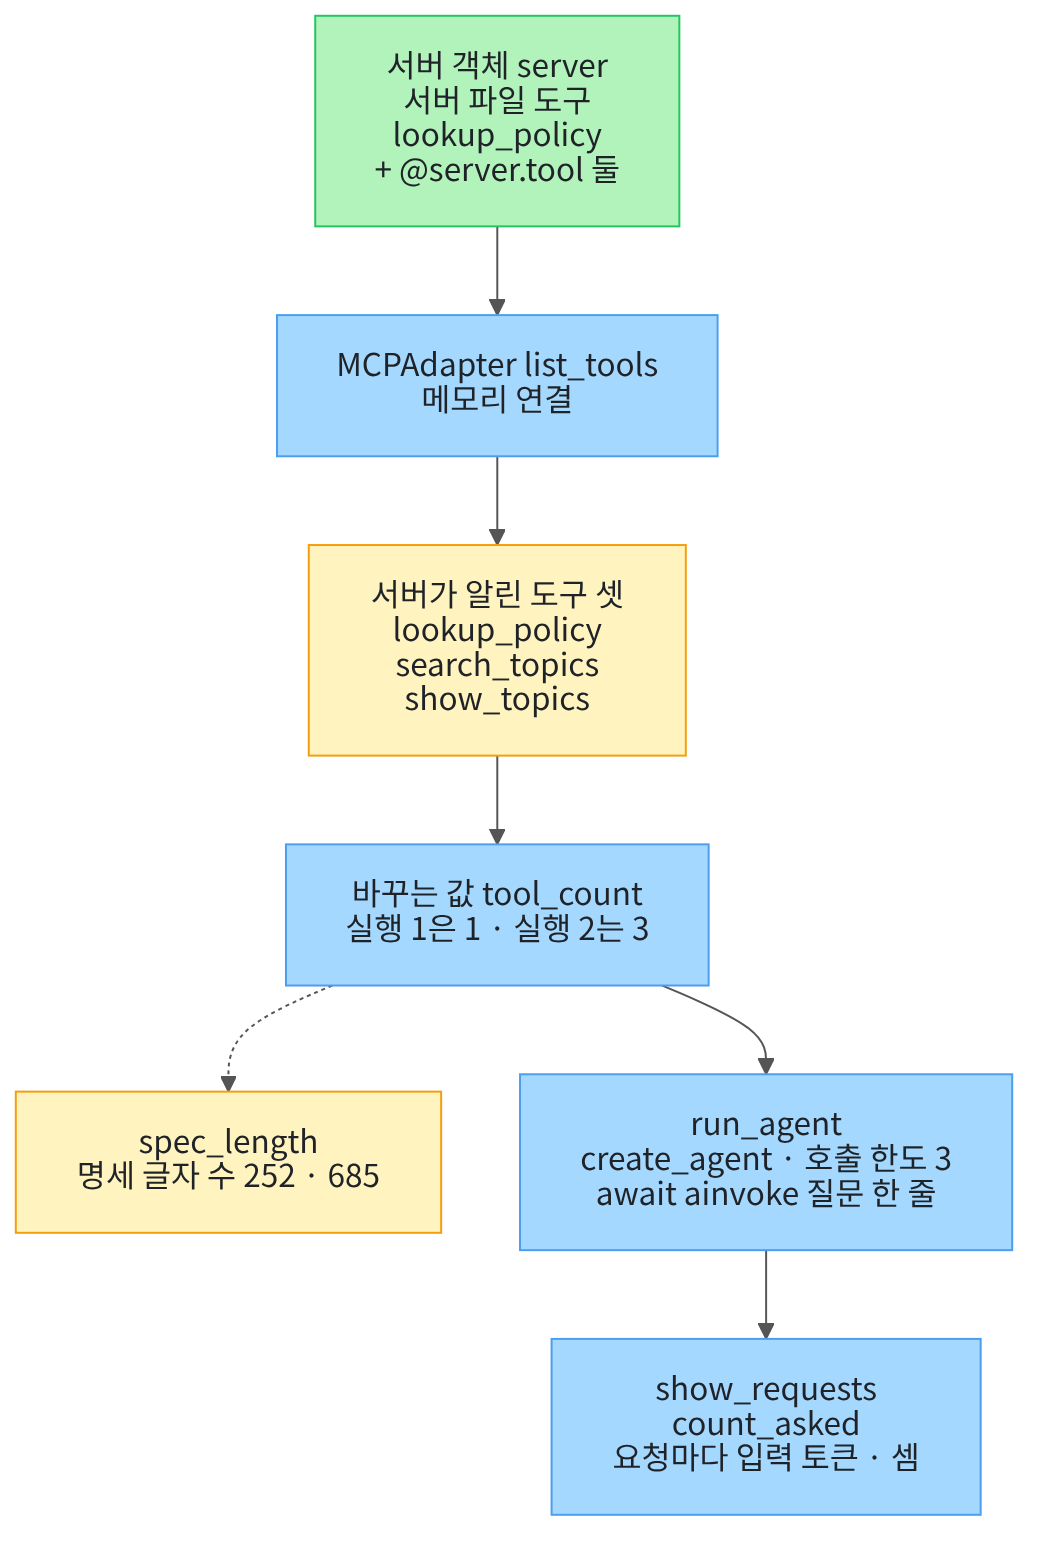

## 1. 준비

이 절은 Ch 28의 실습입니다.
01~05절에서 하나씩 본 기능 가운데 셋을, 자료실 규정에 답하는 에이전트 하나에 모읍니다.
02절의 서버에 도구 붙이기, 04절의 에이전트 연결, 05절의 명세 글자 수와 입력 토큰 세기입니다.
그다음 에이전트에 붙이는 도구 수 하나만 바꿔 두 번 실행하고, 두 결과를 견줍니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
05절과 같은 여섯이고, 04절의 langgraph와 psutil은 쓰지 않아 설치하지 않습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain[mcp]==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "fastmcp==4.0.3" "mcp==2.2.0" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("fastmcp:", version("fastmcp"))
print("mcp:", version("mcp"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
fastmcp: 4.0.3
mcp: 2.2.0
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`, `langchain-core: 1.6.2`, `fastmcp: 4.0.3`이 보입니다.
여섯 판 모두 실습 폴더 잠금과 같습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
04절처럼 모듈 `langchain.mcp`는 베타 경고 한 종류만 끄고 가져옵니다.
마지막 가져오기 줄은 앞에서 배운 함수 다섯을 도구 파일 `connect_tools.py`에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(langchain.mcp는 베타 경고 한 종류만 끄고 가져옵니다)
import runpy
import warnings
from langchain_core._api import LangChainBetaWarning
warnings.filterwarnings("ignore", category=LangChainBetaWarning)
from langchain.mcp import MCPAdapter
from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware
from langchain.chat_models import init_chat_model
from langchain.messages import HumanMessage
# 01절과 앞 챕터에서 배운 함수 다섯은 도구 파일에서 가져옵니다
from connect_tools import estimate_cost, names_of, spec_length, sum_usage, tool_call_names

print("도구 파일에서 가져온 함수:", "estimate_cost, names_of, spec_length, sum_usage, tool_call_names")

도구 파일에서 가져온 함수: estimate_cost, names_of, spec_length, sum_usage, tool_call_names


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: estimate_cost, names_of, spec_length, sum_usage, tool_call_names`가 보입니다.
함수 `names_of`는 01절 4절에서, 함수 `spec_length`는 Ch 19 03절에서 배웠습니다.
함수 `tool_call_names`와 `sum_usage`는 Ch 19 04·05절, `estimate_cost`는 Ch 6 06절에서 배웠습니다.
다섯 모두 04·05절에서 가져온 이름이고, 이 절에서 새로 배우는 이름은 없습니다.

앞에서 배운 함수는 `connect_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-28에 이 모델로 실행한 결과입니다.
temperature 값을 0으로 두어도, 실행마다 답 문장이 달라질 수 있습니다.
이 셀은 모델 객체만 만들고, 모델 요청은 아직 보내지 않습니다.
모델 요청은 5절과 6절의 실행 셀에서만 나갑니다.

## 2. 재료: 도구 셋을 알리는 서버

실습에 쓸 서버는 05절 4절에서 만든 도구 셋 서버와 같습니다.
서버 파일을 이 커널에서 읽고, 그 서버 객체에 도구 둘을 더 붙입니다.
먼저 01절 2절과 같은 셀로 서버 파일의 위치를 찾습니다.

In [5]:
# 작업 폴더에서 본 서버 파일의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["../course_server.py", "course_server.py", "labs/part6/ch28-mcp/course_server.py"]
server_file = None
for candidate in candidates:
    if os.path.exists(candidate):
        server_file = candidate
        break
print("서버 파일을 찾았는가:", server_file is not None)
print("고른 파일 위치:", server_file)
assert server_file is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

서버 파일을 찾았는가: True
고른 파일 위치: labs/part6/ch28-mcp/course_server.py


**결과 읽기** — 출력 줄 `서버 파일을 찾았는가: True`가 보입니다.
교재 출력은 프로젝트 맨 위에서 실행해 셋째 후보 `labs/part6/ch28-mcp/course_server.py`를 골랐습니다.
`notebooks/` 폴더에서 열면 첫 후보 `../course_server.py`가 골라집니다.

다음 셀은 05절 3절과 같은 셀로, 서버 파일을 실행해 서버 객체와 규정 딕셔너리를 받습니다.

In [6]:
# 서버 파일을 실행해 서버 객체와 규정 딕셔너리를 받습니다(02절 6절처럼 runpy.run_path로 읽고, 파일은 고치지 않습니다)
server_names = runpy.run_path(server_file)
server = server_names["mcp"]
policies = server_names["POLICIES"]
print("서버 이름:", server.name)
print("규정 주제:", list(policies))

서버 이름: 교육센터 자료실
규정 주제: ['대출', '운영', '연체']


**결과 읽기** — 출력 줄 `서버 이름: 교육센터 자료실`과 `규정 주제: ['대출', '운영', '연체']`가 보입니다.
변수 `server`는 서버 파일이 만든 서버 객체이고, 변수 `policies`는 규정 딕셔너리입니다.
파일을 실행해 이름을 받았을 뿐이라, 서버 파일은 그대로입니다.

다음 셀은 05절 4절과 같은 셀로, 규정 글에서 낱말이 든 주제어를 찾는 도구를 서버 객체에 붙입니다.
셀의 `@server.tool` 줄은 02절처럼 아래 함수를 서버 객체 `server`의 도구로 등록합니다.

In [7]:
# 서버 객체에 규정 글에서 낱말이 든 주제어를 찾는 도구를 더 붙입니다(서버 파일은 그대로입니다)
@server.tool
def search_topics(word: str):
    """규정 글에 낱말이 든 주제어를 찾습니다. word에는 찾을 낱말을 넣습니다."""
    found = []
    for topic in policies:
        if word in policies[topic]:
            found.append(topic)
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통은 규정 딕셔너리의 주제어를 차례로 보며, 규정 글에 낱말이 든 주제어를 모읍니다.
이 도구는 커널 안의 서버 객체에만 붙고, 서버 파일은 고치지 않습니다.

다음 셀도 05절 4절과 같은 셀로, 인자가 없는 도구 하나를 같은 서버 객체에 더 붙입니다.

In [8]:
# 같은 서버 객체에 규정 주제어 목록을 알려 주는, 인자 없는 도구를 더 붙입니다
@server.tool
def show_topics():
    """자료실 규정의 주제어 목록을 알려 줍니다."""
    return list(policies)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
몸통은 규정 딕셔너리의 주제어를 목록으로 내놓습니다.
이제 서버 객체에는 서버 파일의 `lookup_policy`까지 도구 셋이 붙었습니다.

다음 셀은 이 서버 객체를 05절 4절처럼 메모리 연결로 클래스 `MCPAdapter`에 넘겨 도구를 받습니다.

In [9]:
# 도구 셋이 붙은 서버 객체를 메모리 연결로 MCPAdapter에 넘겨, LangChain 도구 목록으로 받습니다(05절 4절)
practice_adapter = MCPAdapter(server)
served_tools = await practice_adapter.list_tools()
print("서버가 알린 도구:", names_of(served_tools))
print("받은 도구 수:", len(served_tools))

서버가 알린 도구: ['lookup_policy', 'search_topics', 'show_topics']
받은 도구 수: 3


**결과 읽기** — 출력 줄 `서버가 알린 도구: ['lookup_policy', 'search_topics', 'show_topics']`와 `받은 도구 수: 3`이 보입니다.
목록 맨 앞이 `lookup_policy`라서, 실행 1은 목록 앞에서 하나만 골라 이 도구를 붙입니다.
메모리 연결이라 자식 프로세스는 띄우지 않았습니다.
도구를 부를 때에도 이 커널 안의 서버 객체가 도구를 실행합니다.

## 3. 조립하기

조립에는 04절의 에이전트 연결을 씁니다.
Ch 26·27처럼 모델을 부르는 에이전트에는 Ch 22 04절의 호출 한도를 함께 붙입니다.
다음 셀은 04절 5절과 같은 셀로, invoke 한 번에 모델 요청을 3번까지만 허락하는 호출 한도를 만듭니다.

In [10]:
# invoke 한 번에 모델 요청을 3번까지만 허락하는 호출 한도를 만듭니다(Ch 22 04절)
call_limit = ModelCallLimitMiddleware(run_limit=3, exit_behavior="end")
print("한 번 실행의 요청 한도:", call_limit.run_limit)
print("한도에 닿으면:", call_limit.exit_behavior)

한 번 실행의 요청 한도: 3
한도에 닿으면: end


**결과 읽기** — 출력 줄 `한 번 실행의 요청 한도: 3`과 `한도에 닿으면: end`가 보입니다.
04절에서 본 것처럼, 이 한도는 `ainvoke`로 실행해도 실행 한 번마다 셉니다.
두 실행의 에이전트가 이 객체 하나를 함께 씁니다.

다음 셀은 두 실행에 같게 쓸 시스템 메시지 글과 질문을 정합니다.
04절 5절의 에이전트에 준 글과 같은 글입니다.

In [11]:
# 두 실행에 같게 쓸 시스템 메시지 글과 질문을 정합니다(04절 5절과 같은 글)
agent_rule = "교육센터 자료실 규정 질문에는 도구로 규정을 찾아, 찾은 글만 근거로 한국어 한 문장으로 답하세요."
question = "교육센터 자료실은 토요일에 몇 시까지 운영하나요?"
print("시스템 메시지 글:", agent_rule)
print("질문:", question)
print("두 글의 출처: 04절 5절 에이전트에 준 글(실행 전에 정함)")

시스템 메시지 글: 교육센터 자료실 규정 질문에는 도구로 규정을 찾아, 찾은 글만 근거로 한국어 한 문장으로 답하세요.
질문: 교육센터 자료실은 토요일에 몇 시까지 운영하나요?
두 글의 출처: 04절 5절 에이전트에 준 글(실행 전에 정함)


**결과 읽기** — 라벨 `시스템 메시지 글:`과 `질문:` 뒤에 두 글이 보입니다.
라벨 `두 글의 출처:` 뒤에는 두 글을 가져온 곳이 보입니다.
시스템 메시지 글은 규정 질문에 도구로 규정을 찾고, 찾은 글만 근거로 답하라고 정합니다.
질문은 서버 파일의 운영 규정으로 답할 수 있는 질문입니다.
두 글은 실행 전에 정했고, 결과를 보고 바꾸지 않았습니다.

다음 셀은 에이전트에 붙일 도구 목록 하나를 받아, 에이전트를 만들고 한 번 실행하는 조립 함수입니다.
04절 5절의 에이전트 셀과 실행 셀을 한 함수로 모았습니다.
함수 안에서 `await`를 쓰므로, 02절 2절처럼 정의 줄을 `async def`로 씁니다.

In [12]:
# 에이전트에 붙일 도구 목록을 받아 에이전트를 만들고, 질문 한 줄로 한 번 실행해 결과 메시지를 내놓습니다(04절 5절)
async def run_agent(chosen_tools):
    agent = create_agent(model, tools=chosen_tools, system_prompt=agent_rule, middleware=[call_limit])
    first_input = {"messages": [HumanMessage(content=question)]}
    result = await agent.ainvoke(first_input)
    return result["messages"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델·시스템 메시지 글·호출 한도·질문은 앞 셀에서 만든 이름을 그대로 씁니다.
그래서 두 실행 사이에 달라지는 것은 인자로 넘기는 도구 목록 하나뿐입니다.
에이전트의 도구가 비동기로만 불리므로, 04절처럼 `ainvoke`로 실행합니다.

## 4. 결과를 볼 함수

두 실행을 같은 잣대로 보려고, 결과 메시지에서 볼 값을 출력하는 함수 둘을 먼저 적습니다.
첫째 함수 `show_requests`는 모델 응답(`AIMessage`)마다 한 줄씩 출력합니다.
한 줄에는 요청 번호, 그 응답의 도구 호출 요청, 그 요청의 입력 토큰이 들어갑니다.
입력 토큰은 05절처럼 응답의 속성 `usage_metadata`에서 읽습니다.

In [13]:
# 결과 메시지에서 모델 응답마다 도구 호출 요청과 입력 토큰을 한 줄씩 출력하고, 입력 토큰 목록을 내놓습니다
def show_requests(messages):
    input_list = []
    for message in messages:
        if type(message).__name__ == "AIMessage":
            tokens = message.usage_metadata["input_tokens"]
            input_list.append(tokens)
            print("요청", len(input_list), "| 도구 호출 요청:", tool_call_names(message), "| 입력 토큰:", tokens)
    return input_list

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델 응답 하나는 모델 요청 하나의 결과라, 응답마다 한 줄이 요청마다 한 줄입니다.
요청 번호는 지금까지 모은 입력 토큰의 개수라, 첫 응답이 요청 1, 둘째 응답이 요청 2가 됩니다.
함수가 내놓는 입력 토큰 목록은 7절에서 두 실행을 요청마다 견줄 때 씁니다.

둘째 함수 `count_asked`는 도구를 요청한 응답 수를 셉니다.
04절 5절에서 셈 「요청 수 = 도구를 요청한 응답 수 + 1」을 확인한 셀의 반복문을 함수로 옮긴 모양입니다.

In [14]:
# 결과 메시지에서 도구 호출 요청이 하나라도 있는 모델 응답의 수를 세어 내놓습니다
def count_asked(messages):
    asked = 0
    for message in messages:
        if type(message).__name__ == "AIMessage":
            if len(tool_call_names(message)) > 0:
                asked = asked + 1
    return asked

**결과 읽기** — 정의 셀이라 출력이 없습니다.
모델 요청 수는 Ch 19 05절 함수 `sum_usage`가 모델 응답 수로 셉니다.
두 수를 견주면, 한 실행이 셈대로 끝났는지 볼 수 있습니다.

## 5. 실행 1: 도구 하나를 붙인 에이전트

이제 실행 1을 합니다.
서버가 알린 도구 셋 가운데, 목록 앞에서 하나만 골라 에이전트에 붙입니다.
05절 4절처럼 슬라이싱 `[:tool_count]`로 목록 앞에서부터 고릅니다.
붙인 도구의 명세 글자 수도 Ch 19 03절 함수 `spec_length`로 셉니다.

In [15]:
# 실행 1: 서버가 알린 도구 셋 가운데 목록 앞에서 하나만 골라, 이름과 명세 글자 수를 봅니다
tool_count = 1
first_tools = served_tools[:tool_count]
print("붙일 도구:", names_of(first_tools))
print("명세 글자 수:", spec_length(first_tools))

붙일 도구: ['lookup_policy']
명세 글자 수: 252


**결과 읽기** — 출력 줄 `붙일 도구: ['lookup_policy']`와 `명세 글자 수: 252`가 보입니다.
05절 2절에서 센 서버 파일 도구의 명세 글자 수와 같습니다.
메모리 연결로 받아도 같은 도구는 같은 명세라는 것을 05절 4절에서 보았습니다.

다음 셀은 이 도구 하나로 실행 1의 에이전트를 만들어 한 번 실행합니다.
실행 전에 예상해 봅니다.
04절 5절과 같은 질문이라면, 모델은 도구를 몇 번 부르고 요청은 몇 번일까요?

In [16]:
# 실행 1의 에이전트를 만들어 한 번 실행하고, 결과 메시지 수와 마지막 답 글을 봅니다
first_messages = await run_agent(first_tools)
print("결과 메시지 수:", len(first_messages))
print("마지막 답 글:")
print(first_messages[-1].text)

결과 메시지 수: 4
마지막 답 글:
토요일은 17:00까지 운영합니다.


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 결과 메시지의 수가 보입니다.
라벨 줄 `마지막 답 글:` 아래는 모델이 쓴 답입니다.
결과 메시지 수는 모델이 도구를 몇 번 부르느냐에 따라 달라질 수 있습니다.

이번 실행에서는 `결과 메시지 수: 4`였고, 답 글은 `토요일은 17:00까지 운영합니다.`였습니다.
새 커널 두 번과 노트북 밖 다섯 번에서도 결과 메시지는 넷이었습니다.
노트북 밖 다섯 번의 답 글은 모두 「교육센터 자료실은」으로 시작하는 다른 문장이었습니다.
답 글은 모델이 쓴 글이라 실행마다 달라질 수 있어, 결론에 쓰지 않습니다.

다음 셀은 함수 `show_requests`로 실행 1의 모델 응답을 요청마다 봅니다.

In [17]:
# 실행 1의 모델 응답마다 도구 호출 요청과 입력 토큰을 보고, 입력 토큰 목록을 받습니다
print("실행 1의 요청:")
first_inputs = show_requests(first_messages)

실행 1의 요청:
요청 1 | 도구 호출 요청: ['lookup_policy'] | 입력 토큰: 187
요청 2 | 도구 호출 요청: [] | 입력 토큰: 243


**결과 읽기** — 라벨 줄 `실행 1의 요청:` 아래가 실행 1의 요청마다 한 줄입니다.
줄마다 요청 번호, 그 응답의 도구 호출 요청, 그 요청의 입력 토큰이 차례로 보입니다.

이번 실행에서는 요청 1의 응답이 `lookup_policy`를 요청했고, 요청 2의 응답은 도구 요청 없이 답했습니다.
입력 토큰은 요청 1이 187, 요청 2가 243이었습니다.
요청 1의 187은 05절 5절에서 MCP 도구 하나를 알린 첫 요청과 같은 값입니다.
요청 2에는 모델의 도구 호출 요청과 도구 메시지가 더 실려, 입력 토큰이 늘었습니다.
도구 차례와 입력 토큰은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 도구를 요청한 응답 수와 모델 요청 수를 견줍니다.

In [18]:
# 실행 1에서 도구를 요청한 응답 수와 모델 요청 수(Ch 19 05절 함수 sum_usage)를 견줍니다
first_usage = sum_usage(first_messages)
first_asked = count_asked(first_messages)
print("도구를 요청한 응답 수:", first_asked)
print("모델 요청 수:", first_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", first_usage["requests"] == first_asked + 1)

도구를 요청한 응답 수: 1
모델 요청 수: 2
모델 요청 수 = 도구를 요청한 응답 수 + 1: True


**결과 읽기** — 라벨 `도구를 요청한 응답 수:`와 `모델 요청 수:` 뒤에 두 수가 보입니다.
마지막 줄은 04절에서 확인한 셈이 이번 실행에서도 맞는지 보여 줍니다.
셈은 호출 한도에 닿지 않고 답으로 끝난 실행에서 맞습니다.

이번 실행에서는 `도구를 요청한 응답 수: 1`, `모델 요청 수: 2`였고, 셈이 `True`였습니다.
요청 2번은 호출 한도 3 안에 들었습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

## 6. 실행 2: 도구 셋을 붙인 에이전트

실행 2는 값 하나만 바꿉니다.
에이전트에 붙이는 도구 수 `tool_count`를 1에서 3으로 바꿔, 서버가 알린 도구 셋을 모두 붙입니다.
서버·질문·시스템 메시지 글·호출 한도·조립 함수는 실행 1과 같습니다.

In [19]:
# 실행 2: 값 하나만 바꿉니다. 붙이는 도구 수를 3으로 해 도구 셋을 모두 고르고, 이름과 명세 글자 수를 봅니다
tool_count = 3
second_tools = served_tools[:tool_count]
print("붙일 도구:", names_of(second_tools))
print("명세 글자 수:", spec_length(second_tools))

붙일 도구: ['lookup_policy', 'search_topics', 'show_topics']
명세 글자 수: 685


**결과 읽기** — 출력 줄 `붙일 도구: ['lookup_policy', 'search_topics', 'show_topics']`와 `명세 글자 수: 685`가 보입니다.
05절 4절에서 도구 셋의 명세 글자 수를 셀 때와 같은 값입니다.
명세 글자 수는 코드가 정하는 값이라, 다시 실행해도 같습니다.

다음 셀은 이 도구 셋으로 실행 2의 에이전트를 만들어 한 번 실행합니다.
실행 전에 예상해 봅니다.
질문은 운영 규정으로 답할 수 있으니, 모델은 여전히 `lookup_policy`를 부를까요?
도구를 부른 뒤의 둘째 요청은 실행 1과 같은 입력 토큰일까요, 아니면 늘어날까요?

In [20]:
# 실행 2의 에이전트를 만들어 한 번 실행하고, 결과 메시지 수와 마지막 답 글을 봅니다
second_messages = await run_agent(second_tools)
print("결과 메시지 수:", len(second_messages))
print("마지막 답 글:")
print(second_messages[-1].text)

결과 메시지 수: 4
마지막 답 글:
토요일은 17:00까지 운영합니다.


**결과 읽기** — 라벨 `결과 메시지 수:` 뒤에 결과 메시지의 수가 보입니다.
라벨 줄 `마지막 답 글:` 아래는 모델이 쓴 답입니다.

이번 실행에서도 `결과 메시지 수: 4`였고, 답 글은 실행 1과 같은 `토요일은 17:00까지 운영합니다.`였습니다.
결과 메시지 수는 노트북 밖 다섯 번과 새 커널 두 번에서도 넷이었습니다.
답 글은 모델이 쓴 글이라, 두 실행의 답 글이 늘 같다고는 읽지 않습니다.

다음 셀은 함수 `show_requests`로 실행 2의 모델 응답을 요청마다 봅니다.

In [21]:
# 실행 2의 모델 응답마다 도구 호출 요청과 입력 토큰을 보고, 입력 토큰 목록을 받습니다
print("실행 2의 요청:")
second_inputs = show_requests(second_messages)

실행 2의 요청:
요청 1 | 도구 호출 요청: ['lookup_policy'] | 입력 토큰: 252
요청 2 | 도구 호출 요청: [] | 입력 토큰: 308


**결과 읽기** — 라벨 줄 `실행 2의 요청:` 아래가 실행 2의 요청마다 한 줄입니다.
실행 1의 줄과 요청 번호마다 견주어 봅니다.

이번 실행에서도 요청 1의 응답이 `lookup_policy`를 요청했고, 요청 2의 응답은 도구 요청 없이 답했습니다.
붙인 도구가 셋이어도, 모델은 운영 규정 도구 하나만 불렀습니다.
입력 토큰은 요청 1이 252, 요청 2가 308이었습니다.
요청 1의 252는 05절 5절에서 MCP 도구 셋을 알린 첫 요청과 같은 값입니다.
도구 차례와 입력 토큰은 노트북 밖 다섯 번과 새 커널 두 번에서 모두 같았습니다.

다음 셀은 실행 2에서도 셈이 맞는지 봅니다.

In [22]:
# 실행 2에서 도구를 요청한 응답 수와 모델 요청 수를 견줍니다
second_usage = sum_usage(second_messages)
second_asked = count_asked(second_messages)
print("도구를 요청한 응답 수:", second_asked)
print("모델 요청 수:", second_usage["requests"])
print("모델 요청 수 = 도구를 요청한 응답 수 + 1:", second_usage["requests"] == second_asked + 1)

도구를 요청한 응답 수: 1
모델 요청 수: 2
모델 요청 수 = 도구를 요청한 응답 수 + 1: True


**결과 읽기** — 라벨 `도구를 요청한 응답 수:`와 `모델 요청 수:` 뒤에 두 수가 보입니다.
마지막 줄로 실행 2도 셈대로 끝났는지 봅니다.

이번 실행에서도 `도구를 요청한 응답 수: 1`, `모델 요청 수: 2`였고, 셈이 `True`였습니다.
도구를 셋 붙여도 요청 수는 실행 1과 같았습니다.
노트북 밖 다섯 번과 새 커널 두 번에서도 같았습니다.

## 7. 두 실행 견주기

마지막으로 두 실행의 입력 토큰을 요청마다 견줍니다.
두 실행의 요청 수가 같을 때만, 같은 번호의 요청끼리 입력 토큰의 차를 셉니다.
요청 수가 다르면 같은 번호라도 실린 메시지가 달라, 이 셀은 차를 출력하지 않습니다.

In [23]:
# 두 실행의 요청 수가 같으면, 같은 번호의 요청끼리 입력 토큰이 얼마나 늘었는지 봅니다
same_count = len(first_inputs) == len(second_inputs)
print("두 실행의 요청 수가 같은가:", same_count)
if same_count:
    position = 0
    for tokens in first_inputs:
        later = second_inputs[position]
        position = position + 1
        print("요청", position, "| 도구 하나:", tokens, "| 도구 셋:", later, "| 늘어난 입력 토큰:", later - tokens)

두 실행의 요청 수가 같은가: True
요청 1 | 도구 하나: 187 | 도구 셋: 252 | 늘어난 입력 토큰: 65
요청 2 | 도구 하나: 243 | 도구 셋: 308 | 늘어난 입력 토큰: 65


**결과 읽기** — 라벨 `두 실행의 요청 수가 같은가:` 뒤의 값을 먼저 봅니다.
그 값이 참이면, 아래 줄마다 요청 번호와 두 실행의 입력 토큰, 그 차가 보입니다.

이번 실행에서는 `두 실행의 요청 수가 같은가: True`였고, 두 요청 모두 `늘어난 입력 토큰: 65`였습니다.
요청 1은 187에서 252로, 요청 2는 243에서 308로 늘었습니다.
흔들림 확인 다섯 번과 두 커널에서 모두, 두 요청의 늘어난 입력 토큰은 65로 같았습니다.
도구를 부른 뒤의 둘째 요청에도, 붙인 도구 셋의 명세가 첫 요청과 같은 만큼 실린 셈입니다.
노트북 밖 기록에서는 두 실행의 도구 인자와 도구 메시지 글도 같았습니다.

마지막 셀은 두 실행의 토큰 합과 예상 비용을 봅니다.
요금은 Ch 6 06절처럼 2026-09-17 요금표의 100만 토큰당 달러입니다.

In [24]:
# 두 실행의 입력·출력 토큰 합과, 2026-09-17 요금표(100만 토큰당 달러)로 어림한 예상 비용을 봅니다(Ch 6 06절 함수 estimate_cost)
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
first_cost = round(estimate_cost(first_usage, input_rate, cached_input_rate, output_rate), 6)
second_cost = round(estimate_cost(second_usage, input_rate, cached_input_rate, output_rate), 6)
print("실행 1 | 입력 토큰 합:", first_usage["input_tokens"], "| 출력 토큰 합:", first_usage["output_tokens"], "| 예상 비용(달러):", first_cost)
print("실행 2 | 입력 토큰 합:", second_usage["input_tokens"], "| 출력 토큰 합:", second_usage["output_tokens"], "| 예상 비용(달러):", second_cost)
print("입력 토큰 합의 차:", second_usage["input_tokens"] - first_usage["input_tokens"])

실행 1 | 입력 토큰 합: 430 | 출력 토큰 합: 32 | 예상 비용(달러): 0.000467
실행 2 | 입력 토큰 합: 560 | 출력 토큰 합: 32 | 예상 비용(달러): 0.000564
입력 토큰 합의 차: 130


**결과 읽기** — 줄마다 한 실행의 입력·출력 토큰 합과, 라벨 `예상 비용(달러):` 뒤의 어림값이 보입니다.
마지막 줄은 두 실행의 입력 토큰 합의 차입니다.
함수 `sum_usage`가 낸 딕셔너리에는 할인되는 입력 토큰 칸이 없어, 입력 토큰을 모두 입력 요금으로 셌습니다.
예상 비용은 요금표로 어림한 값이고, 청구 금액이 아닙니다.

이번 실행에서는 입력 토큰 합이 실행 1 430, 실행 2 560이라, 차가 `입력 토큰 합의 차: 130`이었습니다.
130은 요청마다 늘어난 65가 요청 수 2만큼 더해진 값입니다.
출력 토큰 합은 두 실행 모두 32였고, 예상 비용은 0.000467달러와 0.000564달러였습니다.
노트북 밖 다섯 번에서 실행 1의 출력 토큰 합은 37로, 이 노트북과 달랐습니다.
출력 토큰과 비용은 모델이 쓴 글에 따라 달라지는 값이라 결론에 쓰지 않습니다.

## 정리

1. 02절 서버에 도구 붙이기, 04절 에이전트 연결, 05절 명세 글자 수와 입력 토큰 세기를 에이전트 하나에 모았습니다.
2. 붙인 도구를 하나에서 셋으로 바꾸자 명세 글자 수가 252에서 685가 되었고, 두 실행 모두 셈대로 요청이 끝났습니다.
3. 흔들림 확인 다섯 번과 두 커널에서 모두, 도구 셋을 붙인 실행은 첫 요청과 둘째 요청에서 입력 토큰이 65씩 많았습니다.

이 절로 Ch 28이 끝납니다.
Ch 29에서는 에이전트를 평가하는 방법을 배웁니다.